## All imports

In [20]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from statsmodels.stats.proportion import proportions_ztest

## Reading file

In [21]:
# Set up dataframe from previous data cleaning
clean_data = pd.read_csv('advertising_funnel_clean.csv')

In [22]:
# Creating 2 groups org.traffic and advertising
clean_data['traffic_type'] = np.where(
    clean_data['ad_channel'] == 'organic_traffic',
    'organic',
    'advertising'
)

## Traffic funnel

In [23]:
# creating traffic funnel
stage_order = [
    'interest',
    'consideration',
    'intent',
    'purchase'
]

traffic_funnel = (
    clean_data
    .groupby(['traffic_type', 'funnel_stage'])['user_id']
    .nunique()
    .unstack(fill_value=0)
)

traffic_funnel = traffic_funnel[stage_order]

traffic_funnel

funnel_stage,interest,consideration,intent,purchase
traffic_type,,,,
advertising,452901,271838,38426,3892
organic,78706,53592,9163,542


In [24]:
# conversion
traffic_conversion = (
    traffic_funnel
    .div(traffic_funnel['interest'], axis=0)
    * 100
)

traffic_conversion.round(2)

funnel_stage,interest,consideration,intent,purchase
traffic_type,,,,
advertising,100.0,60.02,8.48,0.86
organic,100.0,68.09,11.64,0.69


We can see that, in the early stages, organic traffic shows a high level of interest, but once it reaches the purchase stage, users change their minds abruptly, and paid traffic yields more conversions.

In [25]:
# plot configuration
traffic_plot = (
    traffic_conversion
    .reset_index()
    .melt(
        id_vars='traffic_type',
        var_name='funnel_stage',
        value_name='percent'
    )
)

traffic_plot['funnel_stage'] = pd.Categorical(
    traffic_plot['funnel_stage'],
    categories=stage_order,
    ordered=True
)

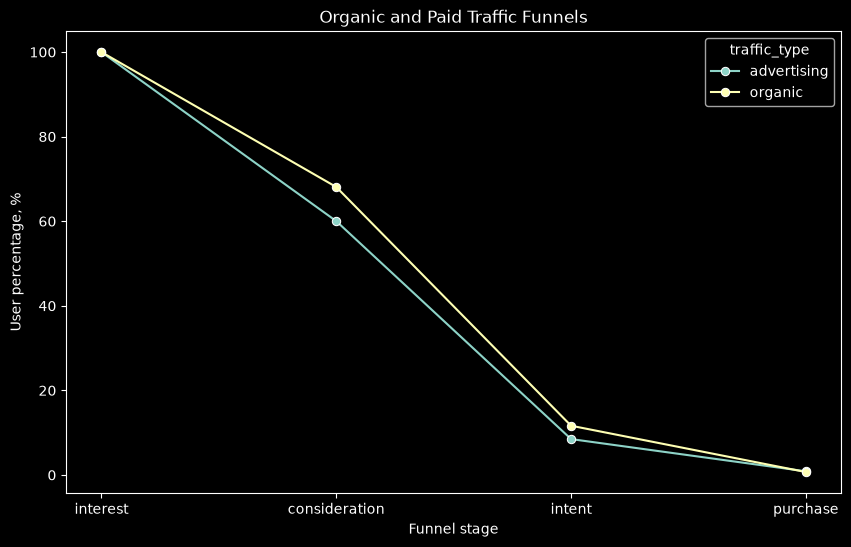

In [26]:
# plot create
plt.figure(figsize=(10, 6))

sns.lineplot(
    data=traffic_plot,
    x='funnel_stage',
    y='percent',
    hue='traffic_type',
    marker='o'
)

plt.xlabel('Funnel stage')
plt.ylabel('User percentage, %')
plt.title('Organic and Paid Traffic Funnels')

plt.show()

In [27]:
# Z-test for statistical significance 
test_results = []

for stage in ['consideration', 'intent', 'purchase']:

    count = np.array([
        traffic_funnel.loc['organic', stage],
        traffic_funnel.loc['advertising', stage]
    ])

    nobs = np.array([
        traffic_funnel.loc['organic', 'interest'],
        traffic_funnel.loc['advertising', 'interest']
    ])

    z_stat, p_value = proportions_ztest(
        count,
        nobs
    )

    test_results.append({
        'stage': stage,
        'organic_share': count[0] / nobs[0] * 100,
        'advertising_share': count[1] / nobs[1] * 100,
        'z_stat': z_stat,
        'p_value': p_value
    })

test_results = pd.DataFrame(test_results)

test_results

,stage,organic_share,advertising_share,z_stat,p_value
0,consideration,68.091378,60.021506,42.886308,0.000000e+00
1,intent,11.642060,8.484415,28.640475,2.106610e-180
2,purchase,0.688639,0.859349,-4.860557,1.170562e-06


Organic traffic attracts a more engaged audience: about 68% of users reach the “consideration” stage, compared to 60% of users from paid traffic, and 11.6% reach the “intent” stage, compared to 8.5%. These differences are statistically significant.

As I mentioned earlier—and as has now been confirmed by testing—organic traffic does not generate the corresponding purchase stage for the users it attracts; paid traffic handles this better.

Translated with DeepL.com (free version)

In [28]:
# funnel to each channel
channel_funnel = (
    clean_data
    .groupby(['ad_channel', 'funnel_stage'])['user_id']
    .nunique()
    .unstack(fill_value=0)
)

channel_funnel = channel_funnel[stage_order]

In [29]:
# Spreadsheet
for stage in ['consideration', 'intent', 'purchase']:
    channel_funnel[f'{stage}_rate'] = (
        channel_funnel[stage]
        / channel_funnel['interest']
        * 100
    )

channel_funnel.round(2)

funnel_stage,interest,consideration,intent,purchase,consideration_rate,intent_rate,purchase_rate
ad_channel,,,,,,,
banner,92003,47541,7625,688,51.67,8.29,0.75
native,19381,12597,412,37,65.00,2.13,0.19
organic_traffic,78706,53592,9163,542,68.09,11.64,0.69
other,3216,1813,232,43,56.37,7.21,1.34
partner_network,66234,24721,4420,450,37.32,6.67,0.68
rich,8922,4657,1238,22,52.20,13.88,0.25
search,224667,134305,27481,3090,59.78,12.23,1.38
video,97960,60880,58,5,62.15,0.06,0.01


According to the data from the columns, we see that the *most valuable* channel for us is the search channel, which has one of the few high purchase and intent coefficients, which generates one of the largest conversions for the product. According to the data collected, this is the *best* channel at the moment.

As for the *worst* channels, this is definitely the video channel that failed to attract an audience and has one of the *lowest conversion rates* and the consequences of intent-purchase, which indicates some difficulties in choosing for this audience, since the 'consideration' item occupies one of the highest positions in attracting audience reach.

## Interpretation to customer

In [30]:
# Presentation for customer
purchase_rates = (
    channel_funnel['purchase_rate']
    .sort_values(ascending=False)
    .reset_index()
)

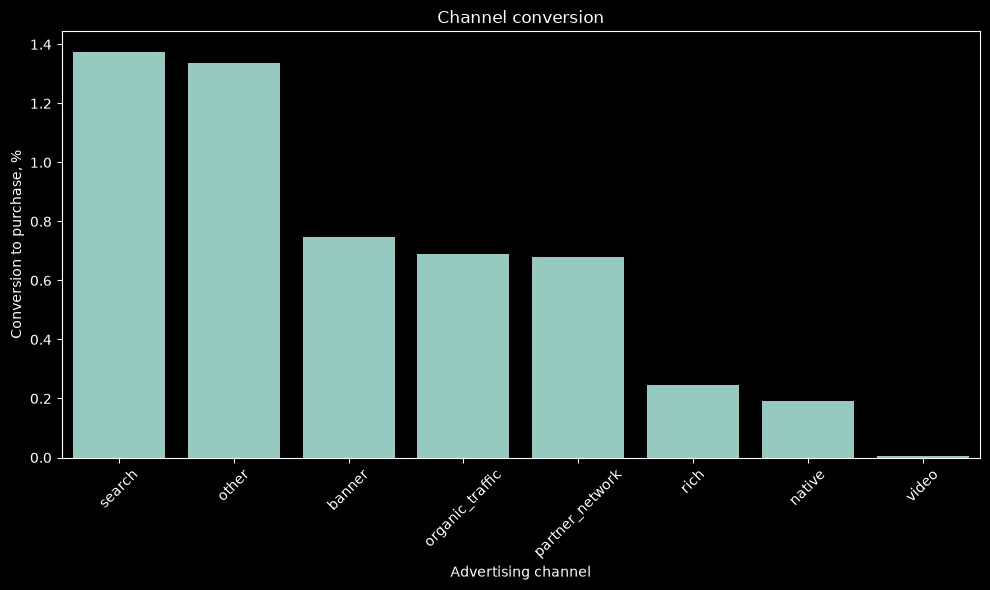

In [31]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=purchase_rates,
    x='ad_channel',
    y='purchase_rate'
)

plt.xlabel('Advertising channel')
plt.ylabel('Conversion to purchase, %')
plt.title('Channel conversion')

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

## Recommendations

It is recommended to shorten the video channel from the current selection or significantly reduce its volume. It attracts a large number of users in the initial stages of the funnel, but it practically does not encourage them to make a purchase. Of the 98,000 users at the first stage, only 5 reached the purchase. At the same time, the channel requires high investments and converts this into significantly lower profits. Therefore, the problem is not the lack of video coverage, but the low quality or low solvency of the attracted audience.

Where to redistribute the budget if you turn off the video channel. After releasing the 120,000 budget, we can redistribute it in such a way that we add most of the budget to the search channel, which has shown a good conversion rate at the moment, and distribute the rest evenly across all other channels to see which channel will become unprofitable this time and form a trend and audience that comes through one or more channels in order to expand the coverage.

## Hypothesis

Hypothesis 1. Redistributing the entire budget from video to search will increase sales.

The reason: the search channel shows one of the highest conversions and the new budget will increase sales.

Hypothesis 2. Redo or change the payment method for the user to increase the conversion rate


The reason: Users often have a good percentage of purchase intentions, but significantly fewer buy the product, so the last stage is not so friendly to them and they may refuse to purchase. An example is the high price of a subscription, the complexity of its design, etc.

Hypothesis 3. The low effectiveness of video is not due to a lack of coverage, but to an irrelevant audience or an ineffective offer.

Reason: High performance in the initial stages and low purchase rates in the channel.